# 00 · Overview: what Purr-ceptron does and how well it works

**Start here.** The short version of the project: what the system does,
how well it works, and what it should not be trusted with.

Everything here is a summary, and each claim names the notebook that
derives it.

| If you want to know | Go to |
|---|---|
| Why joining plant photos to a toxicity list is hard | `01_the_data_problem` |
| How the model was trained, and what the long tail did to it | `02_training` |
| How a species guess becomes a safety verdict | `03_safety_logic` |

One thing first: **the neural network never decides whether a plant is
toxic.** It identifies the species. A separate hand-checked table
decides toxicity. Most of the design follows from that split.

## 1. What it does

One photograph in, one verdict out. Below is the command and its real
output, before any explanation of what happens in between.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from plant_toxicity_checker import cli, plantnet_labels, species_match
from plant_toxicity_checker.config import (
    CANDIDATE_FLOOR,
    DEFAULT_RUN,
    MIN_CONFIDENCE,
    TOXICITY_TABLE_PATH,
)
from plant_toxicity_checker.pipeline import check_image, load_image
from plant_toxicity_checker.plantnet_classifier import PlantNetClassifier
from plant_toxicity_checker.toxicity import load_table

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 92}}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

EXAMPLES_DIR = Path("../docs/images/examples")
TOP_K = 5
# One photo per exit from the flowchart above, in the order the
# flowchart reaches them - so reading the figure top to bottom walks
# the same path as reading the diagram.
EXAMPLES = [
    ("hypericum_perforatum.jpg", "Hypericum perforatum"),
    ("zamia_pumila.jpg", "Zamia pumila"),
    ("daucus_carota.jpg", "Daucus carota"),
    ("calendula_confident.jpg", "Calendula officinalis"),
]

# Colour encodes the TABLE's claim about a species, never the model's
# confidence in it - the two are deliberately independent here, and the
# figure should not let them blur together. Toxic reds, verified-safe
# green, everything weaker in grey: the same ordering the verdict logic
# itself uses, where only a verified exact "no" can ever mean safe.
CATEGORY_COLOR = {
    "exact - toxic": "#b3202c",
    "genus - toxic (direct)": "#b3202c",
    "genus - toxic (inferred)": "#e08a7d",
    "exact - non-toxic": "#2e7d32",
    "genus - non-toxic (direct)": "#9e9e9e",
    "genus - non-toxic (inferred)": "#9e9e9e",
    "exact - unknown": "#9e9e9e",
    "genus - unknown": "#9e9e9e",
    "no match": "#d0d0d0",
}
TIER_COLOR = {"toxic": "#b3202c", "caution": "#c77700",
              "likely_safe": "#2e7d32"}
STAGE1_COLOR = "#2d5f8a"
STAGE2_COLOR = "#6b4c9a"

# PlantNet labels carry the botanical authority ("Hypericum perforatum
# L."); the species-metadata CSV already holds the short form, so reuse
# it rather than trying to strip authors by hand.
SHORT_NAME = {
    row["full_species"]: row["species"]
    for row in plantnet_labels.load_species_rows()
}

ARCHITECTURE_NAMES = {"resnet18": "ResNet-18",
                      "convnextv2_tiny": "ConvNeXt V2-Tiny"}


def run_architecture(run):
    """Read the architecture back out of the checkpoint rather than
    naming it here, so the figures can never claim a model other than
    the one actually loaded."""
    import torch

    from plant_toxicity_checker.train import CHECKPOINTS_DIR

    config = torch.load(CHECKPOINTS_DIR / run / "latest.pt",
                        map_location="cpu", weights_only=False)["config"]
    return ARCHITECTURE_NAMES.get(config["model"], config["model"])


TABLE = load_table(TOXICITY_TABLE_PATH)
TOXICITY_INDEX = species_match.build_toxicity_index(TABLE)
CLASSIFIER = PlantNetClassifier(DEFAULT_RUN)
ARCHITECTURE = run_architecture(DEFAULT_RUN)
verified = sum(1 for entry in TABLE if entry.verified)
print(f"model: {DEFAULT_RUN} ({ARCHITECTURE})")
print(f"toxicity table: {len(TABLE)} entries, {verified} hand-verified")
print(f"thresholds: confidence floor {MIN_CONFIDENCE:.0%}, "
      f"candidate floor {CANDIDATE_FLOOR:.0%}")

model: plantnet_convnextv2_tiny_toxicity_v2 (ConvNeXt V2-Tiny)
toxicity table: 571 entries, 85 hand-verified
thresholds: confidence floor 80%, candidate floor 5%


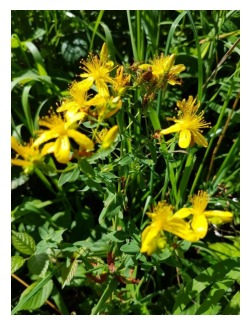

$ python -m plant_toxicity_checker check \
      --image docs/images/examples/hypericum_perforatum.jpg



TOXIC TO CATS - keep away from cats
Best match: Hypericum perforatum L. (56.0%)
- Best match 'Hypericum perforatum L.' is toxic to cats.
- Confidence is low, so it may be another flower.
Top candidates:
   56.0%  Hypericum perforatum L.: TOXIC to cats
   28.8%  Hypericum maculatum Crantz: A relative is toxic to cats
   14.8%  Hypericum hirsutum L.: A relative is toxic to cats
    0.3%  Hypericum calycinum L.: A relative is toxic to cats
    0.0%  Hypericum humifusum L.: A relative is toxic to cats
Note: Only the single most prominent plant in the photo was assessed. Other plants in the photo are NOT checked.


In [2]:
HERO = EXAMPLES_DIR / "hypericum_perforatum.jpg"

figure, axis = plt.subplots(figsize=(3.6, 3.6))
axis.imshow(load_image(HERO))
axis.axis("off")
plt.show()

# Exactly what `python -m plant_toxicity_checker check` prints - the
# same two functions the CLI calls, so this cannot drift from the
# shipped command.
print("$ python -m plant_toxicity_checker check \\")
print(f"      --image docs/images/examples/{HERO.name}\n")
print(cli.format_verdict(check_image(HERO, CLASSIFIER, TABLE), TABLE))

Four parts of that output earn their place.

The **tier** leads, in plain words, because it is all most people will
read. The **species** is named, so anyone who knows plants can check the
claim against the photo. The **reasons** say which rule fired, including
the admission that confidence was low. The **candidate list** shows what
else the model considered and what the table knows about each, so the
alternatives can be looked up instead of taken on trust.

## 2. How the two stages fit together

**Stage 1** is the neural network. It ranks all 1,000 species it knows
by confidence and has no concept of toxicity. **Stage 2** takes that
ranked list, looks each candidate up in a hand-curated table built from
ASPCA listings, and applies fixed rules. Stage 2 has no learned
parameters: the same ranked list always gives the same verdict.

The split is about what happens when the system is wrong. A verdict that
names a species and cites a source can be traced: look at the photo,
look at the plant, look up the ASPCA page, find the step that failed. A
single learned "toxic / not toxic" output gives you nothing to trace. It
would also train on far scarcer and noisier labels than species labels,
and fixing it would mean retraining. With the table separate, a wrong
entry is a one-line edit. [`03_safety_logic`](03_safety_logic.ipynb)
makes the full case.

The rules are deliberately lopsided. Anything uncertain resolves toward
*more* warning, because the two failures are not equal: a needless
warning is an annoyance, a missed toxic plant is a sick cat.

### The flow

The diagram below is the simplified view: correct about which verdict
comes out, but drawn as a chain of tests. The real procedure has one
early exit and then collects reasons, and it distinguishes strengths of
toxic evidence that this version merges.
[`03_safety_logic`](03_safety_logic.ipynb) has the accurate diagram.

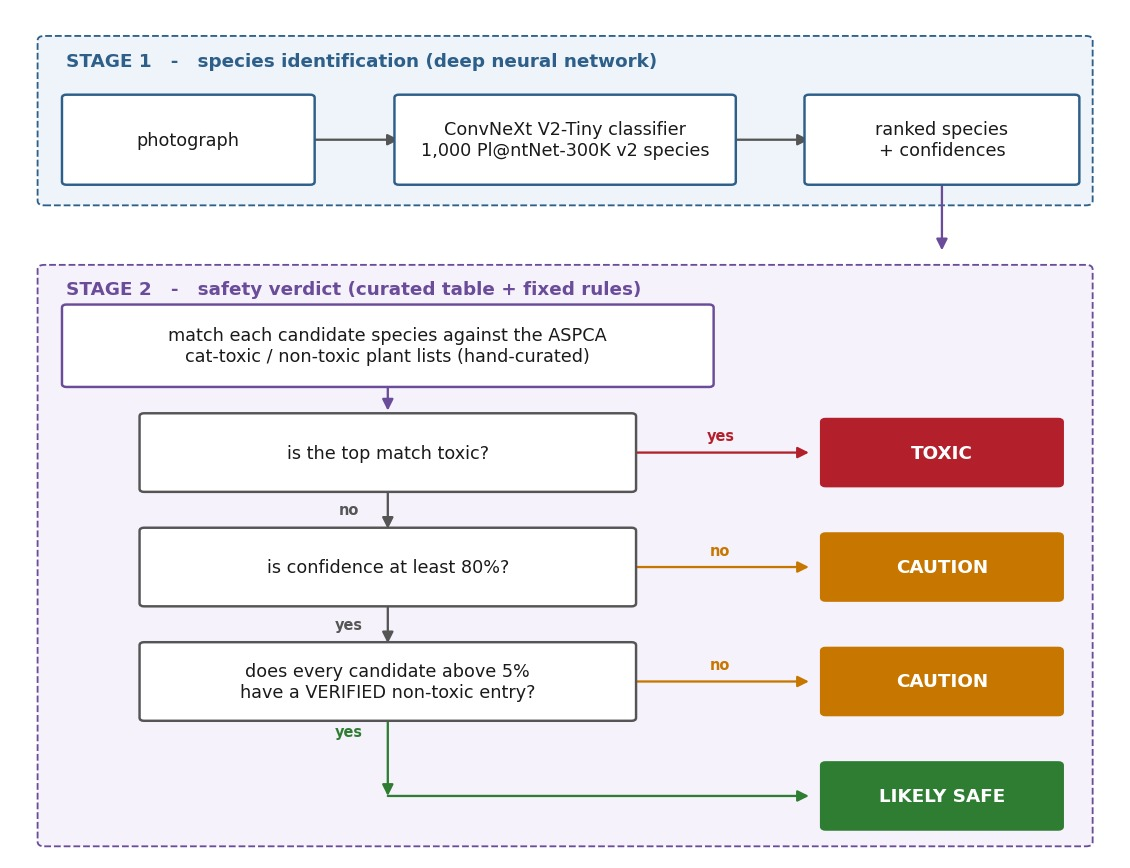

In [3]:
def box(ax, xy, w, h, text, color, fill="#ffffff", fontsize=10.5,
        weight="normal", text_color=None, style="round,pad=0.4"):
    x, y = xy
    ax.add_patch(FancyBboxPatch(
        (x - w / 2, y - h / 2), w, h, boxstyle=style,
        linewidth=1.6, edgecolor=color, facecolor=fill, zorder=2,
    ))
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize,
            color=text_color or "#1a1a1a", weight=weight, zorder=3)
    return x, y


def arrow(ax, start, end, color="#555555", label=None, label_dx=0,
          label_dy=1.8, fontsize=9.5, weight="bold"):
    ax.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=15,
        linewidth=1.5, color=color, zorder=1,
        shrinkA=0, shrinkB=0,
    ))
    if label:
        mx = (start[0] + end[0]) / 2 + label_dx
        my = (start[1] + end[1]) / 2 + label_dy
        ax.text(mx, my, label, ha="center", va="center", fontsize=fontsize,
                color=color, weight=weight, zorder=3)


fig, ax = plt.subplots(figsize=(13, 10))
ax.set_xlim(0, 100)
ax.set_ylim(-11, 100)
ax.axis("off")

# --- stage 1: the only learned component in the system ----------------
ax.add_patch(FancyBboxPatch(
    (3, 75), 94, 21, boxstyle="round,pad=0.6", linewidth=1.2,
    edgecolor=STAGE1_COLOR, facecolor="#eef4fa", linestyle="--", zorder=0,
))
ax.text(5, 93.3,
        "STAGE 1   -   species identification (deep neural network)",
        fontsize=12, weight="bold", color=STAGE1_COLOR, va="center")
box(ax, (16, 83), 22, 11, "photograph", STAGE1_COLOR, fontsize=11.5)
box(ax, (50, 83), 30, 11,
    f"{ARCHITECTURE} classifier\n1,000 Pl@ntNet-300K v2 species",
    STAGE1_COLOR, fontsize=11.5)
box(ax, (84, 83), 24, 11,
    "ranked species\n+ confidences", STAGE1_COLOR, fontsize=11.5)
arrow(ax, (27, 83), (35, 83))
arrow(ax, (65, 83), (72, 83))

arrow(ax, (84, 77.5), (84, 68.5), color=STAGE2_COLOR)

# --- stage 2: fixed rules, no learned parameters ----------------------
ax.add_patch(FancyBboxPatch(
    (3, -9), 94, 75, boxstyle="round,pad=0.6", linewidth=1.2,
    edgecolor=STAGE2_COLOR, facecolor="#f6f2fb", linestyle="--", zorder=0,
))
ax.text(5, 63.5, "STAGE 2   -   safety verdict (curated table + fixed rules)",
        fontsize=12, weight="bold", color=STAGE2_COLOR, va="center")

box(ax, (34, 56), 58, 10,
    "match each candidate species against the ASPCA\n"
    "cat-toxic / non-toxic plant lists (hand-curated)",
    STAGE2_COLOR, fontsize=11.5)
arrow(ax, (34, 50.5), (34, 47.5), color=STAGE2_COLOR)

decisions = [
    (42, "is the top match toxic?", "TOXIC", "toxic"),
    (27, f"is confidence at least {MIN_CONFIDENCE:.0%}?", "CAUTION",
     "caution"),
    (12, f"does every candidate above {CANDIDATE_FLOOR:.0%}\n"
         "have a VERIFIED non-toxic entry?", "CAUTION", "caution"),
]
for i, (y, question, outcome, tier) in enumerate(decisions):
    box(ax, (34, y), 44, 9.5, question, "#555555", fontsize=11.5)
    yes_branch = i == 0  # only the toxic test exits on "yes"
    arrow(ax, (56, y), (72, y), color=TIER_COLOR[tier],
          label="yes" if yes_branch else "no", label_dy=2.2)
    box(ax, (84, y), 21, 8, outcome, TIER_COLOR[tier],
        fill=TIER_COLOR[tier], fontsize=12, weight="bold",
        text_color="white")
    if i < len(decisions) - 1:
        arrow(ax, (34, y - 5.0), (34, decisions[i + 1][0] + 5.0),
              label="no" if yes_branch else "yes", label_dx=-3.5,
              label_dy=0)

arrow(ax, (34, 7.0), (34, -3), label="yes", label_dx=-3.5, label_dy=3.5,
      color=TIER_COLOR["likely_safe"])
arrow(ax, (34, -3), (72, -3), color=TIER_COLOR["likely_safe"])
box(ax, (84, -3), 21, 8, "LIKELY SAFE", TIER_COLOR["likely_safe"],
    fill=TIER_COLOR["likely_safe"], fontsize=12, weight="bold",
    text_color="white")

plt.show()

### The same flow on four photographs

All four are from the Pl@ntNet-300K **test** split, unseen during
training. One photo per exit from the flowchart, in the order the
flowchart reaches them.

| | True species | Decision that settles it | Verdict |
|---|---|---|---|
| 1 | *Hypericum perforatum* (St John's wort) | top match toxic? **yes** | TOXIC |
| 2 | *Zamia pumila* (coontie) | toxic? no. confident? **no** | CAUTION |
| 3 | *Daucus carota* (wild carrot) | toxic? no. confident? yes. alternatives clear? **no** | CAUTION |
| 4 | *Calendula officinalis* (pot marigold) | toxic? no. confident? yes. alternatives clear? **yes** | LIKELY SAFE |

Rows 3 and 4 are the pair to compare. Both correct, both past the
confidence floor, both with a verified non-toxic entry, and only one
comes out safe. The difference is whether a look-alike gathered enough
probability to clear the 5% floor.

The bars encode two separate things. **Length** is the model's
confidence. **Colour** is what the table says, which the model had no
part in deciding.

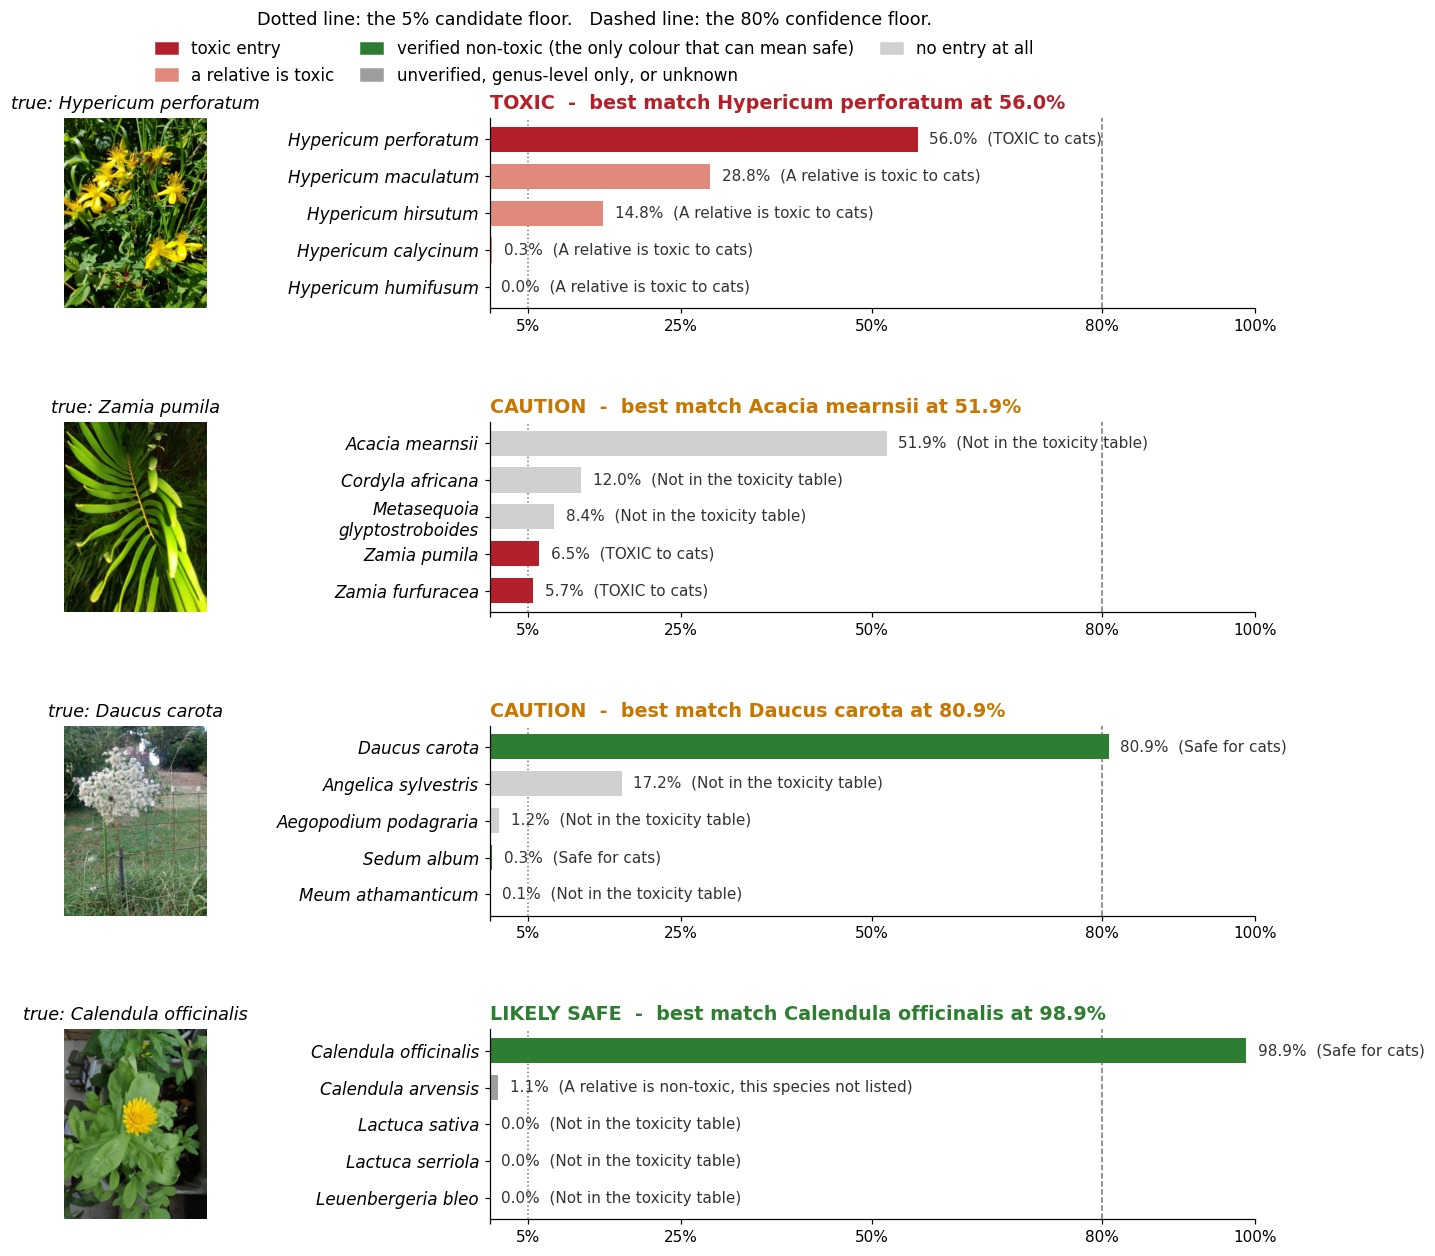

In [4]:
def candidate_color(prediction):
    """An exact non-toxic row that was never verified must not be drawn
    the same green as a verified one - the verdict logic refuses to call
    it safe, so the figure refuses to colour it safe."""
    if prediction["toxicity_category"] == "exact - non-toxic" and \
            not prediction["verified"]:
        return "#9e9e9e"
    return CATEGORY_COLOR[prediction["toxicity_category"]]


def display_name(full_species):
    """A few binomials (*Metasequoia glyptostroboides*) are long enough
    that a one-line tick label runs left out of the bar axes and over
    the photo beside it. Wrap those after the genus so the label width
    stays bounded whatever the layout."""
    name = SHORT_NAME.get(full_species, full_species)
    if len(name) > 22 and " " in name:
        genus, rest = name.split(" ", 1)
        return f"{genus}\n{rest}"
    return name


def draw_example(ax_photo, ax_bars, filename, true_species):
    path = EXAMPLES_DIR / filename
    result = cli.verdict_to_dict(
        check_image(path, CLASSIFIER, TABLE), TABLE, top_k=TOP_K,
    )

    ax_photo.imshow(load_image(path))
    ax_photo.axis("off")
    ax_photo.set_title(f"true: {true_species}", fontsize=11.5,
                       style="italic")

    preds = result["predictions"]
    positions = range(len(preds))[::-1]  # top-1 drawn at the top
    ax_bars.barh(
        list(positions), [p["confidence"] for p in preds],
        color=[candidate_color(p) for p in preds], height=0.68,
    )
    ax_bars.axvline(CANDIDATE_FLOOR, color="#777777", linewidth=1,
                    linestyle=":", zorder=0)
    ax_bars.set_yticks(list(positions))
    ax_bars.set_yticklabels(
        [display_name(p["species"]) for p in preds],
        fontsize=11, style="italic",
    )
    ax_bars.set_xlim(0, 1.0)
    ax_bars.set_xticks([0, CANDIDATE_FLOOR, 0.25, 0.5, MIN_CONFIDENCE, 1.0])
    ax_bars.set_xticklabels(
        ["", f"{CANDIDATE_FLOOR:.0%}", "25%", "50%",
         f"{MIN_CONFIDENCE:.0%}", "100%"], fontsize=10,
    )
    ax_bars.axvline(MIN_CONFIDENCE, color="#777777", linewidth=1,
                    linestyle="--", zorder=0)
    for y, p in zip(positions, preds):
        ax_bars.text(
            p["confidence"] + 0.015, y,
            f"{p['confidence']:.1%}  ({p['toxicity_note']})",
            va="center", fontsize=10, color="#333333",
        )
    tier = result["status"]
    ax_bars.set_title(
        f"{tier.replace('_', ' ').upper()}  -  best match "
        f"{SHORT_NAME.get(result['species'], result['species'])} "
        f"at {result['confidence']:.1%}",
        fontsize=12.5, fontweight="bold", color=TIER_COLOR[tier],
        loc="left",
    )
    return result


fig, axes = plt.subplots(
    len(EXAMPLES), 2, figsize=(15, 13),
    gridspec_kw={"width_ratios": [1, 2.4], "hspace": 0.6, "wspace": 0.36},
)
results = [
    draw_example(axes[i][0], axes[i][1], filename, species)
    for i, (filename, species) in enumerate(EXAMPLES)
]
LEGEND = [
    ("#b3202c", "toxic entry"),
    ("#e08a7d", "a relative is toxic"),
    ("#2e7d32", "verified non-toxic (the only colour that can mean safe)"),
    ("#9e9e9e", "unverified, genus-level only, or unknown"),
    ("#d0d0d0", "no entry at all"),
]
fig.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c, _ in LEGEND],
    labels=[label for _, label in LEGEND],
    loc="upper center", bbox_to_anchor=(0.5, 0.945), ncol=3, frameon=False,
    fontsize=11, handlelength=1.3, columnspacing=1.6,
)
fig.suptitle(
    "Dotted line: the 5% candidate floor.   Dashed line: the 80% "
    "confidence floor.",
    fontsize=11.5, y=0.955,
)
plt.show()

In [5]:
for (filename, true_species), result in zip(EXAMPLES, results):
    print(f"{true_species} ({filename})  ->  {result['status'].upper()}")
    for reason in result["reasons"]:
        print(f"    - {reason}")
    print()

Hypericum perforatum (hypericum_perforatum.jpg)  ->  TOXIC
    - Best match 'Hypericum perforatum L.' is toxic to cats.
    - Confidence is low, so it may be another flower.

Zamia pumila (zamia_pumila.jpg)  ->  CAUTION
    - Confidence 52% is below 80%; treat as toxic.
    - No verified non-toxic entry for 'Acacia mearnsii De Wild.'; treat as toxic.
    - No verified non-toxic entry for 'Cordyla africana Lour.'; treat as toxic.
    - No verified non-toxic entry for 'Metasequoia glyptostroboides Hu & W.C.Cheng'; treat as toxic.
    - Plausible alternative 'Zamia pumila L.' (6%) is toxic to cats.
    - Plausible alternative 'Zamia furfuracea L.f. ex Aiton' (6%) is toxic to cats.

Daucus carota (daucus_carota.jpg)  ->  CAUTION
    - No verified non-toxic entry for 'Angelica sylvestris L.'; treat as toxic.

Calendula officinalis (calendula_confident.jpg)  ->  LIKELY_SAFE
    - 'Calendula officinalis L.' is verified non-toxic to cats and the match is confident. Still check with a vet if a 

### What the four photos show

**1. *Hypericum perforatum*, TOXIC at 56.0%.** 56% would fail the next
test down, but that test is never reached: the toxic check comes first
and has no confidence floor. What the model is unsure *between* also
matters. The runners-up are two more *Hypericum*, pink because a species
in that genus carries a toxic entry, so no route to a non-toxic answer
existed.

**2. *Zamia pumila*, CAUTION at 51.9%.** The model is wrong here: on 17
training photos it puts *Acacia mearnsii* first and the true species
fourth. Confidence catches it before the table is consulted, and two
toxic *Zamia* clear the 5% floor anyway. Section 4 is where
identification degrades; this is what stops that becoming dangerous.

**3. *Daucus carota*, CAUTION at 80.9%.** Nothing went wrong, which
makes it the interesting one. Correct, past the floor, verified
non-toxic, and still a warning, because *Angelica sylvestris* holds
17.2% with no entry at all. The runner-up is a different genus in
Apiaceae, a family full of look-alikes ranging from edible to lethal,
so the caution is earned rather than pedantic.

**4. *Calendula officinalis*, LIKELY SAFE at 98.9%.** Green needs every
condition at once, including nothing above 5% left to check. Against row
3: both correct, both verified non-toxic, differing only in whether a
look-alike stayed above the floor.

The candidate-by-candidate walkthrough is in
[`03_safety_logic`](03_safety_logic.ipynb). None of the four can show a
false reassurance, the one failure that hurts a cat. That takes the
full-split numbers in section 5.

## 3. Headline numbers

Both models, on the held-out **test** split. The ResNet-18 is the
benchmark, trained on the Pl@ntNet-300K paper's recipe and retrained
here because the paper reports on dataset v1 and this uses v2. The
ConvNeXt V2-Tiny ships, and adds square-root frequency sampling for the
imbalance plus the toxicity-aware cost term. Derivation in
[`02_training`](02_training.ipynb).

In [6]:
import pandas as pd

OUTPUTS_DIR = Path("../outputs")
BASELINE_RUN = "plantnet-baseline"


def load_eval(path):
    return json.loads((OUTPUTS_DIR / path).read_text(encoding="utf-8"))


evals = {
    "ResNet-18 (benchmark)":
        load_eval(f"{BASELINE_RUN}/eval_test.json"),
    "ConvNeXt V2-Tiny (shipped)":
        load_eval(f"{DEFAULT_RUN}/eval_test_epoch30_ema.json"),
}

headline = pd.DataFrame({
    name: {
        "top-1": e["top_1"],
        "top-5": e["top_5"],
        "macro-average top-1": e["macro_top_1"],
        "macro-average top-5": e["macro_top_5"],
        "toxic/non-toxic confusion": e["toxic_confusion"]["confusion_rate"],
    }
    for name, e in evals.items()
})
display(headline.style.format("{:.1%}").set_caption(
    "Pl@ntNet-300K v2 test split. Lower is better for the last row only."
))

,ResNet-18 (benchmark),ConvNeXt V2-Tiny (shipped)
top-1,81.4%,81.9%
top-5,95.8%,95.6%
macro-average top-1,35.7%,42.6%
macro-average top-5,64.8%,66.5%
toxic/non-toxic confusion,0.9%,0.3%


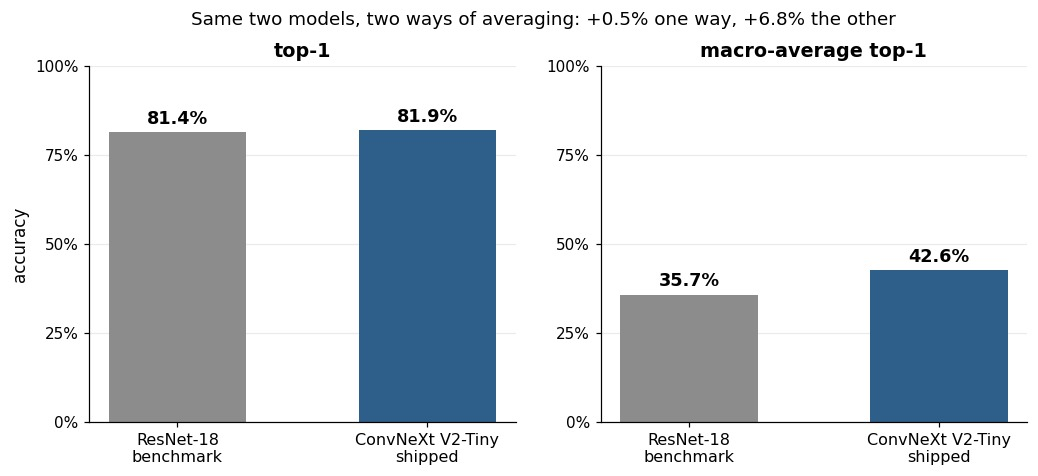

In [7]:
# Plain top-1 weights every PHOTO equally, so the few species holding
# most of the photos dominate it. Macro-average weights every SPECIES
# equally. Putting them side by side is the whole point: the shipped
# model barely moves on one and jumps on the other.
PAIRS = [("top-1", "top_1"), ("macro-average top-1", "macro_top_1")]
MODEL_COLOR = {"ResNet-18 (benchmark)": "#8c8c8c",
               "ConvNeXt V2-Tiny (shipped)": "#2d5f8a"}

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for axis, (title, key) in zip(axes, PAIRS):
    names = list(evals)
    values = [evals[n][key] for n in names]
    bars = axis.bar(range(len(names)), values,
                    color=[MODEL_COLOR[n] for n in names], width=0.55)
    axis.bar_label(bars, labels=[f"{v:.1%}" for v in values],
                   padding=3, fontsize=11.5, fontweight="bold")
    axis.set_xticks(range(len(names)))
    axis.set_xticklabels(["ResNet-18\nbenchmark", "ConvNeXt V2-Tiny\nshipped"],
                         fontsize=10.5)
    axis.set_ylim(0, 1.0)
    axis.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    axis.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
    axis.set_title(title, fontsize=12.5, fontweight="bold")
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)

delta_plain = (evals["ConvNeXt V2-Tiny (shipped)"]["top_1"]
               - evals["ResNet-18 (benchmark)"]["top_1"])
delta_macro = (evals["ConvNeXt V2-Tiny (shipped)"]["macro_top_1"]
               - evals["ResNet-18 (benchmark)"]["macro_top_1"])
axes[0].set_ylabel("accuracy", fontsize=11)
figure.suptitle(
    f"Same two models, two ways of averaging: {delta_plain:+.1%} one "
    f"way, {delta_macro:+.1%} the other",
    fontsize=12, y=1.0,
)
plt.show()

**Plain top-1 barely moves, and that is the finding.** It weights every
photograph equally, so the few species holding most of the dataset
decide it. A model can get much better or much worse at the other 800
without shifting it.

**Macro-average top-1 weights every species equally**, which is why the
Pl@ntNet-300K paper prefers it here, and the gap is **7 points**. The
gain sits in species plain top-1 is too coarse to report on. Section 4
shows which.

**The confusion rate is the number this project exists to move.** It
counts how often the top prediction lands on the wrong side of the
toxic/non-toxic boundary. The toxicity-aware objective cuts it from
0.86% to 0.27%, a 69% relative drop, at no measurable accuracy cost.

## 4. Accuracy is not spread evenly

One accuracy number hides the biggest caveat. Pl@ntNet-300K is severely
long-tailed: a few species have thousands of photos, most have a
handful. The model is good at the first group, weak at the second, and
the headline number is decided by the first.

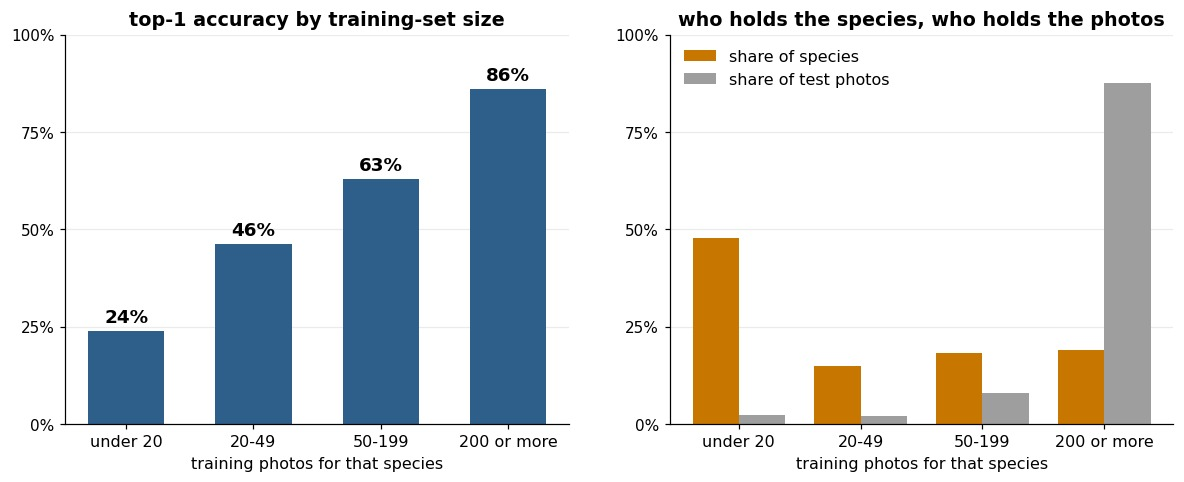

477 of 1000 species have under 20 training photos.
They are 48% of the species but only 2.3% of the test photos, and top-1 on them is 23.9%.
The 191 species with 200+ photos are 88% of the test set at 86.1%.


In [8]:
breakdown = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN /
     "species_breakdown_test_epoch30.json").read_text(encoding="utf-8")
)
buckets = breakdown["buckets"]
order = ["<20", "20-49", "50-199", "200+"]
BUCKET_LABEL = {"<20": "under 20", "20-49": "20-49", "50-199": "50-199",
                "200+": "200 or more"}

n_species = [buckets[b]["n_species"] for b in order]
n_images = [buckets[b]["n"] for b in order]
top1 = [buckets[b]["top1_accuracy"] for b in order]
total_species, total_images = sum(n_species), sum(n_images)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))

bars = axes[0].bar(range(len(order)), top1, color="#2d5f8a", width=0.6)
axes[0].bar_label(bars, labels=[f"{v:.0%}" for v in top1], padding=3,
                  fontsize=12, fontweight="bold")
axes[0].set_ylim(0, 1.0)
axes[0].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[0].set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
axes[0].set_title("top-1 accuracy by training-set size", fontsize=12.5,
                  fontweight="bold")
axes[0].grid(axis="y", alpha=0.25)
axes[0].set_axisbelow(True)

# The second panel is the part that reframes the first: the bucket the
# model is worst at is also the bucket holding most of the SPECIES and
# almost none of the PHOTOS, which is exactly why plain accuracy cannot
# see it.
width = 0.38
positions = range(len(order))
axes[1].bar([p - width / 2 for p in positions],
            [n / total_species for n in n_species], width,
            label="share of species", color="#c77700")
axes[1].bar([p + width / 2 for p in positions],
            [n / total_images for n in n_images], width,
            label="share of test photos", color="#9e9e9e")
axes[1].set_ylim(0, 1.0)
axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[1].set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
axes[1].set_title("who holds the species, who holds the photos",
                  fontsize=12.5, fontweight="bold")
axes[1].legend(fontsize=10.5, frameon=False)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)

for axis in axes:
    axis.set_xticks(list(positions))
    axis.set_xticklabels([BUCKET_LABEL[b] for b in order], fontsize=10.5)
    axis.set_xlabel("training photos for that species", fontsize=10.5)
plt.show()

rare = buckets["<20"]
common = buckets["200+"]
print(f"{rare['n_species']} of {total_species} species have under 20 "
      f"training photos.")
print(f"They are {rare['n_species'] / total_species:.0%} of the species "
      f"but only {rare['n'] / total_images:.1%} of the test photos, "
      f"and top-1 on them is {rare['top1_accuracy']:.1%}.")
print(f"The {common['n_species']} species with 200+ photos are "
      f"{common['n'] / total_images:.0%} of the test set at "
      f"{common['top1_accuracy']:.1%}.")

Read the panels together. The left says the model is weak on rare
species. The right says those species are **most of the label space and
almost none of the photographs**: 477 of 1,000 species, 2.3% of the test
set. Hence 81% plain against 43% macro-average. The two numbers measure
different populations and neither is wrong.

The practical consequence is narrow. A species the model has barely seen
usually will not be identified confidently, so it will not clear the 80%
floor, so it resolves to CAUTION instead of a confident wrong answer.
The long tail costs *usefulness*, not safety.

## 5. Where verdicts actually land

The finished pipeline over every validation photograph, using the full
probability distribution for each one, exactly as the shipped `check`
command does.

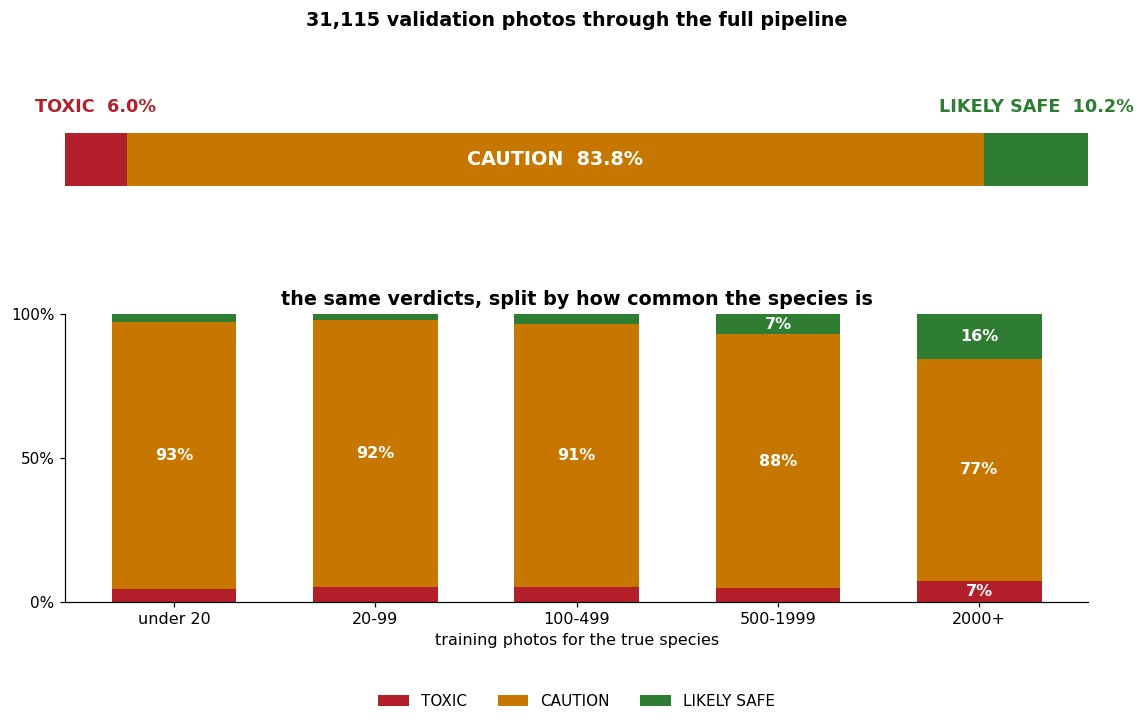

726 of 1,000 species have no toxicity-table entry at all.
28 species have a VERIFIED non-toxic entry - only those can ever produce LIKELY SAFE.


In [9]:
TIER_ORDER = ["toxic", "caution", "likely_safe"]
TIER_LABEL = {"toxic": "TOXIC", "caution": "CAUTION",
              "likely_safe": "LIKELY SAFE"}

tiers_path = OUTPUTS_DIR / DEFAULT_RUN / "verdict_tiers_val.json"
tier_data = json.loads(tiers_path.read_text(encoding="utf-8"))
counts = tier_data["tiers"]
total = sum(counts.values())
shares = [counts.get(t, 0) / total for t in TIER_ORDER]

figure, axes = plt.subplots(
    2, 1, figsize=(12, 6.4),
    gridspec_kw={"height_ratios": [1, 2.1], "hspace": 0.55},
)

left = 0.0
for tier, share in zip(TIER_ORDER, shares):
    axes[0].barh(0, share, left=left, color=TIER_COLOR[tier], height=0.5)
    # A narrow slice cannot hold its own label without running off the
    # end of the bar, so those get labelled above it instead.
    if share >= 0.15:
        axes[0].text(left + share / 2, 0, f"{TIER_LABEL[tier]}  {share:.1%}",
                     ha="center", va="center", color="white", fontsize=12.5,
                     fontweight="bold")
    else:
        axes[0].text(left + share / 2, 0.42,
                     f"{TIER_LABEL[tier]}  {share:.1%}", ha="center",
                     va="bottom", color=TIER_COLOR[tier], fontsize=11.5,
                     fontweight="bold")
    left += share
axes[0].set_xlim(0, 1)
axes[0].set_ylim(-0.35, 0.95)
axes[0].axis("off")
axes[0].set_title(f"{total:,} validation photos through the full pipeline",
                  fontsize=12.5, fontweight="bold", pad=22)

# Same verdicts, split by how many training photos the TRUE species had.
# LIKELY SAFE is not distributed evenly across the label space, and the
# reason is worth seeing rather than asserting.
BUCKETS = [("0-20", "under 20"), ("20-100", "20-99"), ("100-500", "100-499"),
           ("500-2000", "500-1999"), ("2000-1000000000", "2000+")]
by_count = tier_data["by_train_count"]
positions = range(len(BUCKETS))
bottoms = [0.0] * len(BUCKETS)
for tier in TIER_ORDER:
    values = [by_count[key].get(tier, 0) / sum(by_count[key].values())
              for key, _ in BUCKETS]
    axes[1].bar(list(positions), values, bottom=bottoms, width=0.62,
                color=TIER_COLOR[tier], label=TIER_LABEL[tier])
    for position, value, bottom in zip(positions, values, bottoms):
        if value >= 0.06:
            axes[1].text(position, bottom + value / 2, f"{value:.0%}",
                         ha="center", va="center", color="white",
                         fontsize=10.5, fontweight="bold")
    bottoms = [b + v for b, v in zip(bottoms, values)]
axes[1].set_xticks(list(positions))
axes[1].set_xticklabels([label for _, label in BUCKETS], fontsize=10.5)
axes[1].set_xlabel("training photos for the true species", fontsize=10.5)
axes[1].set_ylim(0, 1)
axes[1].set_yticks([0, 0.5, 1.0])
axes[1].set_yticklabels(["0%", "50%", "100%"], fontsize=10)
axes[1].set_title("the same verdicts, split by how common the species is",
                  fontsize=12.5, fontweight="bold")
axes[1].legend(fontsize=10, frameon=False, ncol=3,
               loc="lower center", bbox_to_anchor=(0.5, -0.42))
plt.show()

# How much of the label space the table can even speak to - the number
# that explains the chart above.
categories = {}
for row in plantnet_labels.load_species_rows():
    match = species_match.lookup_toxicity(row["species"], TOXICITY_INDEX)
    category = species_match.toxicity_category(match)
    categories[category] = categories.get(category, 0) + 1

verified_safe = sum(
    1 for row in plantnet_labels.load_species_rows()
    if (lambda m: m.status == "exact" and m.exact_row.toxic_to_cats == "no"
        and m.exact_row.verified)(
            species_match.lookup_toxicity(row["species"], TOXICITY_INDEX))
)
print(f"{categories['no match']} of 1,000 species have no toxicity-table "
      f"entry at all.")
print(f"{verified_safe} species have a VERIFIED non-toxic entry - only "
      f"those can ever produce LIKELY SAFE.")

**CAUTION dominates, and that is about the table, not the classifier.**
726 of the 1,000 species the model can name have no entry at all, and 28
have a verified non-toxic one. LIKELY SAFE needs the top match to be one
of those 28 *and* every plausible alternative cleared, so most
photographs cannot reach it however good the model gets.

Green reaches 10% only because of *which* 28 species those are: common,
heavily photographed plants that cover far more of the validation set
than 28 out of 1,000 suggests.

The lower panel shows the same split by species frequency. LIKELY SAFE
is near-absent below 100 training photos and reaches 16% at the top. Two
causes push the same way: rare species rarely clear the confidence floor
(section 4), and the verified entries cluster among common plants. Both
land on CAUTION, which is the right direction to fail.

The bottleneck is hand-curation, not machine learning. Each verified row
widens what the system can be definite about, and training accuracy does
not substitute for it.

## 6. What this cannot do

**It knows 1,000 species.** Anything outside Pl@ntNet-300K v2's label
space is not rejected, it is mapped to the nearest species the model
knows, and still gets a confident-looking name. Nothing in a ranked list
can say "none of the above".

**It is weak on rare species.** Top-1 is 23.9% for the 477 species under
20 training photos, against 86.1% for the 191 with 200 or more. Those
mostly resolve to CAUTION rather than confident mistakes, but the system
is least useful exactly where a plant is unusual.

**The toxicity table is thin.** 726 of 1,000 species have no entry. 34
have a hand-verified exact entry: 28 non-toxic, 6 toxic. The rest are
genus-level inferences or unknown, and neither can produce LIKELY SAFE.

**Its training photos are not the photos people take.** Pl@ntNet-300K is
citizen-science field photography: plants outdoors, in daylight, shot
deliberately. Houseplants, cut flowers and bouquets are out of
distribution. How much worse it gets is unmeasured, because there is no
labelled set of those photos.

**One plant per photograph.** Only the most prominent plant is assessed.
A bouquet with one lily among safe flowers can return a non-toxic
verdict for the wrong plant.

**No veterinary review.** The table was assembled from ASPCA listings by
one person who is not a vet. It is a prompt to check, not advice. If a
cat has eaten something, call a vet.

## 7. Where to go next

- **"Why is the toxicity table so small? Can't you scrape it?"** The
  matching is harder than it looks: common names collide ("lily" covers
  both lethal and harmless plants), and ASPCA's listings do not line up
  with PlantNet's species.
  [`01_the_data_problem`](01_the_data_problem.ipynb).

- **"How was the model trained, and what did the long tail do to it?"**
  The recipe, the imbalance handling, the toxicity-aware cost term, and
  the comparison behind shipping plain cross-entropy plus that term.
  [`02_training`](02_training.ipynb).

- **"Why those thresholds? Why does unverified mean unsafe?"** The rules
  candidate by candidate, and what happens with a species the table has
  never heard of. [`03_safety_logic`](03_safety_logic.ipynb).

- **"Can I run it?"** `python -m plant_toxicity_checker check --image
  <path>`. The README covers setup and checkpoints.